In [1]:
!nvidia-smi

Sat Oct 24 01:26:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q ultralytics roboflow

In [3]:
from roboflow import Roboflow

rf = Roboflow(api_key="DTems6qESoiGAo9b2CXK")

project = rf.workspace("nycu-ki2pm").project("dms-hpytf")
version = project.version(1)
dataset = version.download("yolov11")

print("Dataset location:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to DMS-1 in yolov11:: 100%|██████████| 18166/18166 [00:02<00:00, 8522.38it/s] 


Dataset location: /content/DMS-1


In [4]:
import os
import glob
from collections import Counter

label_files = glob.glob(
    os.path.join(dataset.location, "**", "labels", "*.txt"),
    recursive=True
)

class_counts = Counter()

for label_file in label_files:
    with open(label_file, "r") as f:
        for line in f:
            if line.strip():
                class_id = int(float(line.split()[0]))
                class_counts[class_id] += 1

print("Classes found:")

for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count} annotations")

Classes found:
Class 0: 4241 annotations
Class 1: 6655 annotations
Class 2: 9055 annotations
Class 3: 9855 annotations
Class 4: 1511 annotations
Class 5: 3705 annotations
Class 6: 6545 annotations


In [5]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import defaultdict

root = Path(dataset.location)

samples = defaultdict(list)

for split in ["train", "valid", "test"]:
    label_dir = root / split / "labels"
    image_dir = root / split / "images"

    if not label_dir.exists():
        continue

    for label_file in label_dir.glob("*.txt"):

        with open(label_file, "r") as f:
            lines = [x.strip() for x in f.readlines() if x.strip()]

        ids = set(int(float(x.split()[0])) for x in lines)

        image_path = None

        for ext in [".jpg", ".jpeg", ".png", ".JPG", ".PNG"]:
            candidate = image_dir / (label_file.stem + ext)

            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            continue

        for cid in ids:
            if len(samples[cid]) < 3:
                samples[cid].append((image_path, label_file))


CLASS ID: 0


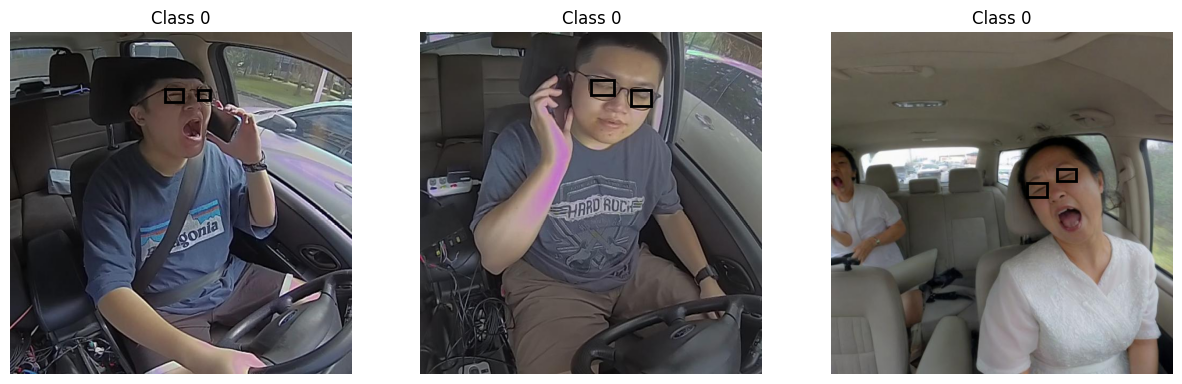


CLASS ID: 1


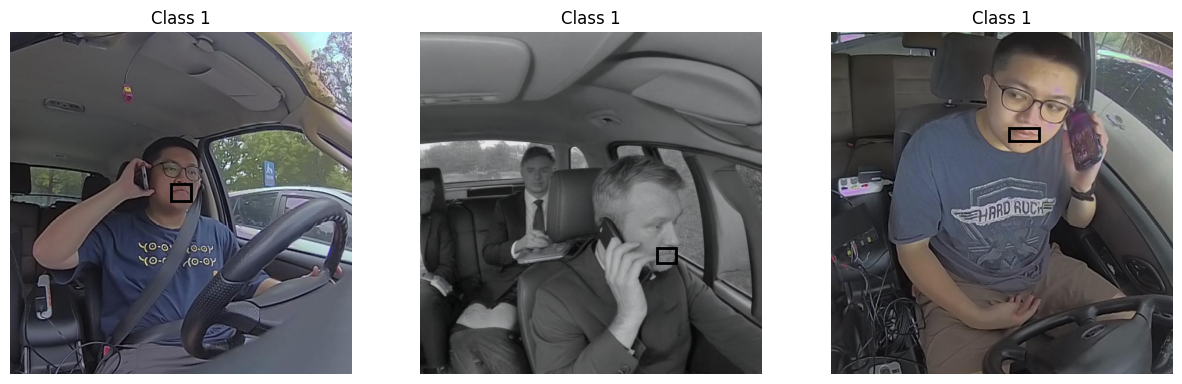


CLASS ID: 2


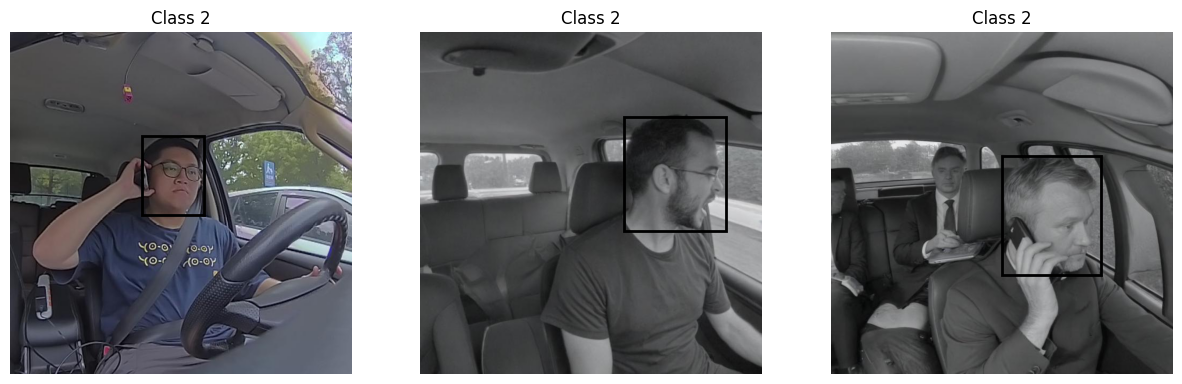


CLASS ID: 3


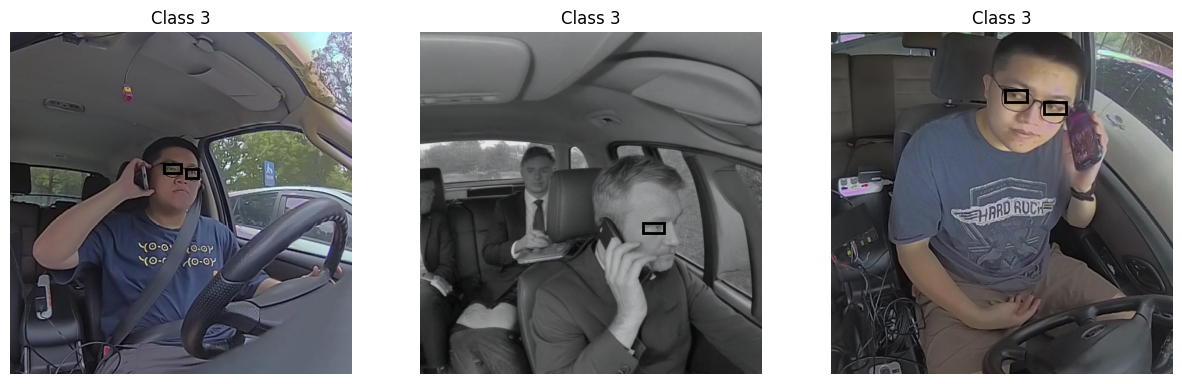


CLASS ID: 4


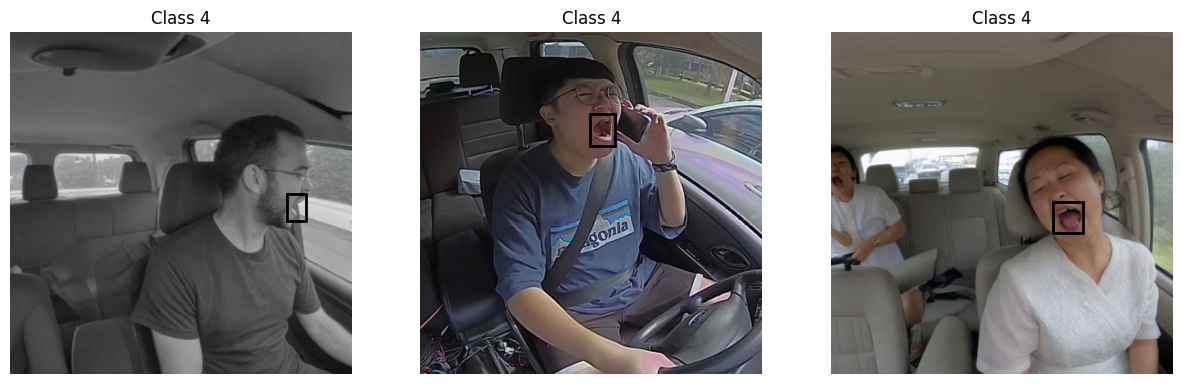


CLASS ID: 5


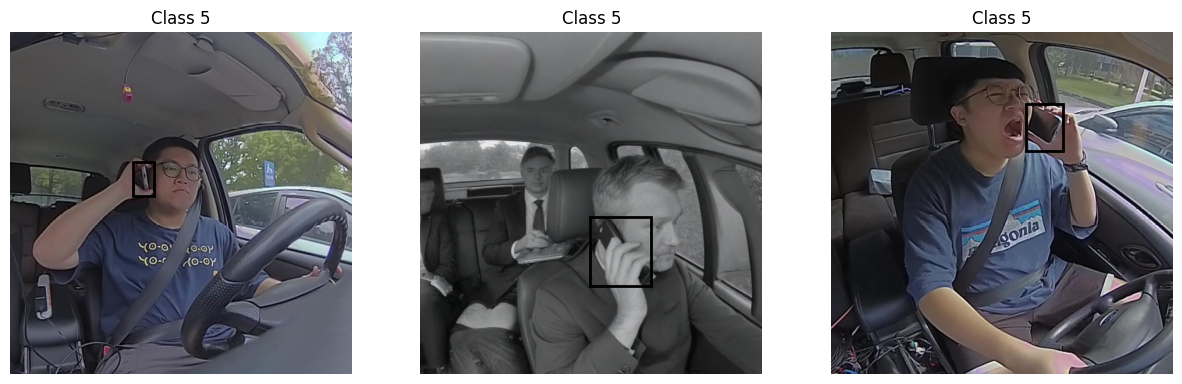


CLASS ID: 6


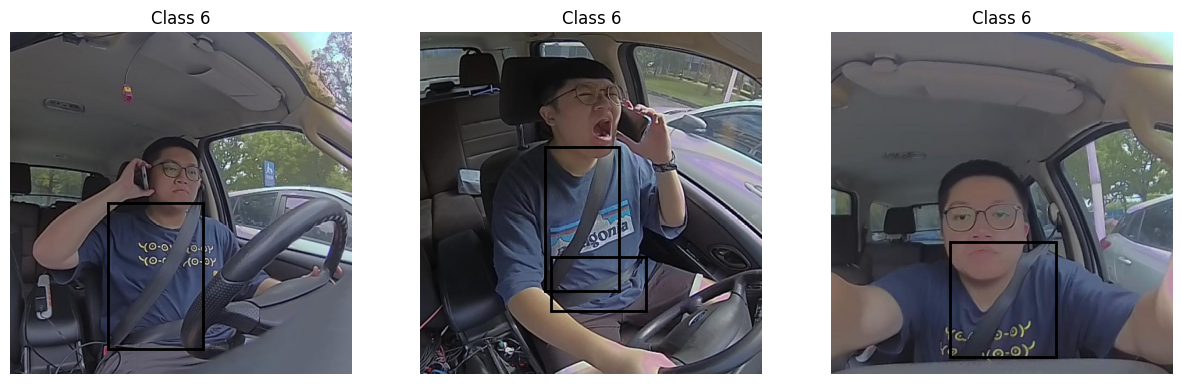

In [6]:
for class_id in sorted(samples.keys()):

    print("\n==============================")
    print("CLASS ID:", class_id)
    print("==============================")

    fig, axes = plt.subplots(1, len(samples[class_id]), figsize=(15, 5))

    if len(samples[class_id]) == 1:
        axes = [axes]

    for ax, (image_path, label_path) in zip(axes, samples[class_id]):

        image = Image.open(image_path).convert("RGB")

        width, height = image.size

        ax.imshow(image)

        with open(label_path, "r") as f:
            for line in f:

                parts = line.strip().split()

                if len(parts) < 5:
                    continue

                cid = int(float(parts[0]))

                if cid != class_id:
                    continue

                x, y, w, h = map(float, parts[1:5])

                x1 = (x - w / 2) * width
                y1 = (y - h / 2) * height

                rect = patches.Rectangle(
                    (x1, y1),
                    w * width,
                    h * height,
                    linewidth=2,
                    fill=False
                )

                ax.add_patch(rect)

        ax.set_title(f"Class {class_id}")
        ax.axis("off")

    plt.show()

In [7]:
OLD_CLASS_TO_NAME = {
    0: "drowsiness",
    2: "driver_distraction",
    4: "yawning",
    5: "phone_usage",
    6: "seat_belt_detected"
}

In [8]:
TARGET_NAMES = [
    "drowsiness",
    "driver_distraction",
    "yawning",
    "phone_usage",
    "seat_belt_detected"
]

name_to_new_id = {
    name: i for i, name in enumerate(TARGET_NAMES)
}

old_to_new = {
    old_id: name_to_new_id[name]
    for old_id, name in OLD_CLASS_TO_NAME.items()
}

print("Old -> New mapping:", old_to_new)

Old -> New mapping: {0: 0, 2: 1, 4: 2, 5: 3, 6: 4}


In [9]:
import os
import shutil
from pathlib import Path

source_root = Path(dataset.location)
clean_root = Path("/content/DMS_5CLASS")

if clean_root.exists():
    shutil.rmtree(clean_root)

image_extensions = [
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
]

for split in ["train", "valid", "test"]:

    source_images = source_root / split / "images"
    source_labels = source_root / split / "labels"

    target_images = clean_root / split / "images"
    target_labels = clean_root / split / "labels"

    target_images.mkdir(parents=True, exist_ok=True)
    target_labels.mkdir(parents=True, exist_ok=True)

    if not source_labels.exists():
        continue

    kept_images = 0

    for label_file in source_labels.glob("*.txt"):

        new_lines = []

        with open(label_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) < 5:
                    continue

                old_id = int(float(parts[0]))

                if old_id in old_to_new:

                    new_id = old_to_new[old_id]

                    parts[0] = str(new_id)

                    new_lines.append(" ".join(parts))

        if len(new_lines) == 0:
            continue

        image_file = None

        for ext in image_extensions:

            candidate = source_images / (label_file.stem + ext)

            if candidate.exists():
                image_file = candidate
                break

        if image_file is None:
            continue

        shutil.copy2(
            image_file,
            target_images / image_file.name
        )

        with open(target_labels / label_file.name, "w") as f:
            f.write("\n".join(new_lines))

        kept_images += 1

    print(split, "images:", kept_images)

train images: 6837
valid images: 1698
test images: 540


In [10]:
import yaml

clean_yaml = clean_root / "data.yaml"

data_config = {
    "path": str(clean_root),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": TARGET_NAMES
}

with open(clean_yaml, "w") as f:
    yaml.safe_dump(
        data_config,
        f,
        sort_keys=False
    )

print(open(clean_yaml).read())

path: /content/DMS_5CLASS
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- drowsiness
- driver_distraction
- yawning
- phone_usage
- seat_belt_detected



In [11]:
from collections import Counter
import glob

counts = Counter()

clean_labels = glob.glob(
    "/content/DMS_5CLASS/**/labels/*.txt",
    recursive=True
)

for label_file in clean_labels:

    with open(label_file, "r") as f:

        for line in f:

            if line.strip():

                class_id = int(
                    float(line.split()[0])
                )

                counts[class_id] += 1

print("Final 5-class dataset:")

for class_id, count in sorted(counts.items()):

    print(
        class_id,
        TARGET_NAMES[class_id],
        "=",
        count
    )

Final 5-class dataset:
0 drowsiness = 4241
1 driver_distraction = 9055
2 yawning = 1511
3 phone_usage = 3705
4 seat_belt_detected = 6545


In [12]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("YOLO11s ready")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO11s ready


In [13]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("YOLO11s ready")

YOLO11s ready


In [14]:
results = model.train(
    data=str(clean_yaml),

    epochs=50,

    imgsz=640,

    batch=8,

    device=0,

    workers=2,

    patience=50,

    pretrained=True,

    save=True,

    plots=True,

    project="/content/driver_behavior_training",

    name="driver_behavior_yolo11s"
)

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/DMS_5CLASS/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=driver_behavior_yolo11s, nbs=64, nms=None, opset=None, optim

In [15]:
from google.colab import files

uploaded = files.upload()

Saving 20000101120217-00-00-lady-000000_1010_jpg.rf.079c35ed3f634e4a05041e918f140cf9.jpg to 20000101120217-00-00-lady-000000_1010_jpg.rf.079c35ed3f634e4a05041e918f140cf9.jpg


In [16]:
image_path = list(uploaded.keys())[0]

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    save=True
)


image 1/1 /content/20000101120217-00-00-lady-000000_1010_jpg.rf.079c35ed3f634e4a05041e918f140cf9.jpg: 640x640 1 drowsiness, 1 driver_distraction, 1 phone_usage, 24.0ms
Speed: 1.0ms preprocess, 24.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


In [17]:
from google.colab import files

uploaded = files.upload()

Saving 20000101120217-00-00-lady-000000_1060_jpg.rf.46b5fcda3a6bfc3fbeacdeb99634f568.jpg to 20000101120217-00-00-lady-000000_1060_jpg.rf.46b5fcda3a6bfc3fbeacdeb99634f568.jpg


In [18]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    save=True
)

Saving 20000101120217-00-00-lady-000000_1060_jpg.rf.46b5fcda3a6bfc3fbeacdeb99634f568.jpg to 20000101120217-00-00-lady-000000_1060_jpg.rf.46b5fcda3a6bfc3fbeacdeb99634f568 (1).jpg

image 1/1 /content/20000101120217-00-00-lady-000000_1060_jpg.rf.46b5fcda3a6bfc3fbeacdeb99634f568 (1).jpg: 640x640 2 drowsinesss, 1 driver_distraction, 1 phone_usage, 24.1ms
Speed: 1.1ms preprocess, 24.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


In [19]:
import glob
from google.colab import files

# Search for any results.csv files in the content workspace
found_files = glob.glob('/content/**/results.csv', recursive=True)

if found_files:
    print(f"Found the following results files: {found_files}")
    # Download the first one found
    target_file = found_files[0]
    print(f"Downloading {target_file}...")
    files.download(target_file)
else:
    print("No results.csv files were found in /content. Let's see what directories exist.")
    !ls -R /content

Found the following results files: ['/content/driver_behavior_training/driver_behavior_yolo11s/results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
import os
import shutil

source_folder = '/content/driver_behavior_training'
destination_folder = '/content/drive/MyDrive/driver_behavior_training'

if os.path.exists(source_folder):
    shutil.copytree(
        source_folder,
        destination_folder,
        dirs_exist_ok=True
    )
    print("Folder and all files saved to Google Drive!")
else:
    print("Source folder not found. Please check its location.")

Folder and all files saved to Google Drive!
